In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')


folder_name = "Ctrl+Alt+Del_DataVers_AnavaUGM"
base_path = f'/content/drive/MyDrive/{folder_name}'


if os.path.exists(base_path):
    print(f"Berhasil terhubung ke folder: {folder_name}")
    print("Isi folder:", os.listdir(base_path))
else:
    print(f"Folder tidak ditemukan! Pastikan nama folder di Drive sesuai: {folder_name}")

data_path = os.path.join(base_path, 'data')
notebooks_path = os.path.join(base_path, 'notebooks')
models_path = os.path.join(base_path, 'models')
sub_path = os.path.join(base_path, 'submissions')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Berhasil terhubung ke folder: Ctrl+Alt+Del_DataVers_AnavaUGM
Isi folder: ['notebooks', 'data', 'models', 'submissions']


In [ ]:
#load data
import pandas as pd
import numpy as np

df_train = pd.read_csv(f'{data_path}/train.csv')
df_test = pd.read_csv(f'{data_path}/test.csv')

In [ ]:
#cek info data
df_train.info()
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000000 entries, 0 to 7999999
Data columns (total 25 columns):
 #   Column            Dtype  
---  ------            -----  
 0   Trip_ID           object 
 1   Timestamp         object 
 2   Pickup_Lat        float64
 3   Pickup_Long       float64
 4   Dropoff_Lat       float64
 5   Dropoff_Long      float64
 6   GPS_Accuracy_M    float64
 7   Distance_KM       float64
 8   Est_Price_IDR     float64
 9   Surge_Multiplier  float64
 10  Accel_X           float64
 11  Accel_Y           float64
 12  Accel_Z           float64
 13  Gyro_Z            float64
 14  Pickup_Zone       object 
 15  Dropoff_Zone      object 
 16  Device_FP         object 
 17  Promo_Code        object 
 18  Car_Model         object 
 19  Payment_Method    object 
 20  Weather           object 
 21  Traffic           object 
 22  Battery_Level     object 
 23  Signal_Strength   object 
 24  Trip_Label        object 
dtypes: float64(12), object(13)
memory usage: 1.5+

In [ ]:
#Cek missing value
missing_value = df_train.isna().sum()
missing_value

,0
Trip_ID,0
Timestamp,1637893
Pickup_Lat,929348
Pickup_Long,611083
Dropoff_Lat,1914440
Dropoff_Long,1556029
GPS_Accuracy_M,1504090
Distance_KM,941317
Est_Price_IDR,1151401
Surge_Multiplier,612307


In [ ]:
# Membersihkan kolom battery, mengubah dari string ke float
def clean_battery(df):
    df["Battery_Level"] = (
        df["Battery_Level"]
        .astype(str)
        .str.replace("%", "", regex=False)
        .replace("nan", np.nan)
        .astype(float)
    )
    return df

df_train = clean_battery(df_train)
df_test  = clean_battery(df_test)

In [ ]:
#membersihkan kolom kategori
#ubah object ke category dan diisi unknown (train)
cat_cols_category = ["Pickup_Zone", "Dropoff_Zone", "Car_Model"]
cat_cols_str = ["Device_FP", "Promo_Code", "Payment_Method","Weather", "Traffic", "Signal_Strength"]

for col in cat_cols_category:
    df_train[col] = df_train[col].astype("category")
    if "Unknown" not in df_train[col].cat.categories:
        df_train[col] = df_train[col].cat.add_categories(["Unknown"])
    df_train[col] = df_train[col].fillna("Unknown")

#ubah object ke str dan diisi unknown (train)
for col in cat_cols_str:
    df_train[col] = df_train[col].astype(str).fillna("Unknown")

#ubah object ke category dan diisi unknown (test)
for col in cat_cols_category:
    df_test[col] = df_test[col].astype("category")
    df_test[col] = df_test[col].cat.set_categories(
        df_train[col].cat.categories
    )
    df_test[col] = df_test[col].fillna("Unknown")

#ubah object ke str dan diisi unknown (test)
for col in cat_cols_str:
    df_test[col] = df_test[col].astype(str).fillna("Unknown")

In [ ]:
#membersihkan kolom numerik
#ubah float64 ke float32 untuk menghemat ram
float_cols = df_train.select_dtypes(include="float64").columns
df_train[float_cols] = df_train[float_cols].astype(np.float32)
df_test[float_cols]  = df_test[float_cols].astype(np.float32)

In [ ]:
#cek info data
df_train.info()
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000000 entries, 0 to 7999999
Data columns (total 25 columns):
 #   Column            Dtype   
---  ------            -----   
 0   Trip_ID           object  
 1   Timestamp         object  
 2   Pickup_Lat        float32 
 3   Pickup_Long       float32 
 4   Dropoff_Lat       float32 
 5   Dropoff_Long      float32 
 6   GPS_Accuracy_M    float32 
 7   Distance_KM       float32 
 8   Est_Price_IDR     float32 
 9   Surge_Multiplier  float32 
 10  Accel_X           float32 
 11  Accel_Y           float32 
 12  Accel_Z           float32 
 13  Gyro_Z            float32 
 14  Pickup_Zone       category
 15  Dropoff_Zone      category
 16  Device_FP         object  
 17  Promo_Code        object  
 18  Car_Model         category
 19  Payment_Method    object  
 20  Weather           object  
 21  Traffic           object  
 22  Battery_Level     float32 
 23  Signal_Strength   object  
 24  Trip_Label        object  
dtypes: category(3), fl

In [ ]:
#Cek jumlah dan presentase missing value
missing_value = df_train.isna().sum()
missing_percentage = (missing_value / len(df_train)) * 100

df_missing_value = pd.DataFrame({"Missing Value":missing_value, "Missing Percentage":missing_percentage})
df_missing_value = df_missing_value.sort_values(by="Missing Value", ascending=False)
df_missing_value

,Missing Value,Missing Percentage
Dropoff_Lat,1914440,23.930500
Accel_Z,1840229,23.002862
Battery_Level,1746399,21.829988
Timestamp,1637893,20.473662
Accel_X,1608442,20.105525
Dropoff_Long,1556029,19.450363
GPS_Accuracy_M,1504090,18.801125
Est_Price_IDR,1151401,14.392512
Accel_Y,1081337,13.516713
Distance_KM,941317,11.766462


In [ ]:
# Menghitung skewness untuk semua kolom numerik di data train
skew_values = df_train[['Dropoff_Lat','Accel_Z','Battery_Level','Accel_X','Dropoff_Long',
                        'GPS_Accuracy_M','Est_Price_IDR','Accel_Y','Distance_KM','Pickup_Lat',
                        'Gyro_Z','Surge_Multiplier','Pickup_Long']].skew()
print(skew_values)

Dropoff_Lat        -0.000762
Accel_Z             0.001062
Battery_Level      -0.000338
Accel_X            -0.000109
Dropoff_Long       -0.000498
GPS_Accuracy_M     -0.000221
Est_Price_IDR       1.010846
Accel_Y             0.000828
Distance_KM         0.480927
Pickup_Lat         -0.001120
Gyro_Z              0.002068
Surge_Multiplier   -0.000145
Pickup_Long        -0.000478
dtype: float32


In [ ]:
#isi missing value berdasarkan grafik dan nilai skewness (train)
df_train['Dropoff_Lat'] = df_train['Dropoff_Lat'].fillna(df_train['Dropoff_Lat'].mean())
df_train['Accel_Z'] = df_train['Accel_Z'].fillna(df_train['Accel_Z'].mean())
df_train['Battery_Level'] = df_train['Battery_Level'].fillna(df_train['Battery_Level'].mean())
df_train['Accel_X'] = df_train['Accel_X'].fillna(df_train['Accel_X'].median())
df_train['Dropoff_Long'] = df_train['Dropoff_Long'].fillna(df_train['Dropoff_Long'].mean())
df_train['GPS_Accuracy_M'] = df_train['GPS_Accuracy_M'].fillna(df_train['GPS_Accuracy_M'].median())
df_train['Est_Price_IDR'] = df_train['Est_Price_IDR'].fillna(df_train['Est_Price_IDR'].median())
df_train['Accel_Y'] = df_train['Accel_Y'].fillna(df_train['Accel_Y'].mean())
df_train['Distance_KM'] = df_train['Distance_KM'].fillna(df_train['Distance_KM'].median())
df_train['Pickup_Lat'] = df_train['Pickup_Lat'].fillna(df_train['Pickup_Lat'].median())
df_train['Gyro_Z'] = df_train['Gyro_Z'].fillna(df_train['Gyro_Z'].mean())
df_train['Surge_Multiplier'] = df_train['Surge_Multiplier'].fillna(df_train['Surge_Multiplier'].median())
df_train['Pickup_Long'] = df_train['Pickup_Long'].fillna(df_train['Pickup_Long'].median())

missing_value = df_train.isna().sum()
missing_value

,0
Trip_ID,0
Timestamp,1637893
Pickup_Lat,0
Pickup_Long,0
Dropoff_Lat,0
Dropoff_Long,0
GPS_Accuracy_M,0
Distance_KM,0
Est_Price_IDR,0
Surge_Multiplier,0


In [ ]:
#Cek jumlah dan presentase missing value (test)
missing_value = df_test.isna().sum()
missing_percentage = (missing_value / len(df_test)) * 100

df_missing_value = pd.DataFrame({"Missing Value":missing_value, "Missing Percentage":missing_percentage})
df_missing_value = df_missing_value.sort_values(by="Missing Value", ascending=False)
df_missing_value

,Missing Value,Missing Percentage
Distance_KM,396051,9.901275
Battery_Level,393943,9.848575
Pickup_Long,371655,9.291375
Est_Price_IDR,342705,8.567625
Accel_Y,339435,8.485875
Pickup_Lat,339061,8.476525
Gyro_Z,319265,7.981625
Surge_Multiplier,280388,7.009700
GPS_Accuracy_M,270534,6.763350
Accel_X,238902,5.972550


In [ ]:
# Menghitung skewness untuk semua kolom numerik di data test
skew_values = df_test[['Dropoff_Lat','Accel_Z','Battery_Level','Accel_X','Dropoff_Long',
                        'GPS_Accuracy_M','Est_Price_IDR','Accel_Y','Distance_KM','Pickup_Lat',
                        'Gyro_Z','Surge_Multiplier','Pickup_Long']].skew()
print(skew_values)

Dropoff_Lat        -0.001616
Accel_Z            -0.000412
Battery_Level       0.000236
Accel_X             0.000388
Dropoff_Long        0.001552
GPS_Accuracy_M      0.000205
Est_Price_IDR       1.012998
Accel_Y            -0.000854
Distance_KM         0.480388
Pickup_Lat         -0.000223
Gyro_Z             -0.004903
Surge_Multiplier   -0.000360
Pickup_Long         0.000715
dtype: float32


In [ ]:
# Mengisi missing value pada df_test berdasarkan karakteristik data
df_test['Dropoff_Lat'] = df_test['Dropoff_Lat'].fillna(df_test['Dropoff_Lat'].mean())
df_test['Accel_Z'] = df_test['Accel_Z'].fillna(df_test['Accel_Z'].mean())
df_test['Battery_Level'] = df_test['Battery_Level'].fillna(df_test['Battery_Level'].mean())
df_test['Accel_X'] = df_test['Accel_X'].fillna(df_test['Accel_X'].median()) # Karena multimodal (banyak puncak)
df_test['Dropoff_Long'] = df_test['Dropoff_Long'].fillna(df_test['Dropoff_Long'].mean())
df_test['GPS_Accuracy_M'] = df_test['GPS_Accuracy_M'].fillna(df_test['GPS_Accuracy_M'].median())
df_test['Est_Price_IDR'] = df_test['Est_Price_IDR'].fillna(df_test['Est_Price_IDR'].median()) # Karena skewness > 1
df_test['Accel_Y'] = df_test['Accel_Y'].fillna(df_test['Accel_Y'].mean())
df_test['Distance_KM'] = df_test['Distance_KM'].fillna(df_test['Distance_KM'].median()) # Karena visual ber-ekor
df_test['Pickup_Lat'] = df_test['Pickup_Lat'].fillna(df_test['Pickup_Lat'].median())
df_test['Gyro_Z'] = df_test['Gyro_Z'].fillna(df_test['Gyro_Z'].mean())
df_test['Surge_Multiplier'] = df_test['Surge_Multiplier'].fillna(df_test['Surge_Multiplier'].median())
df_test['Pickup_Long'] = df_test['Pickup_Long'].fillna(df_test['Pickup_Long'].median())

# Mengecek kembali apakah masih ada missing value
missing_value = df_test.isna().sum()
missing_value

,0
Trip_ID,0
Timestamp,163030
Pickup_Lat,0
Pickup_Long,0
Dropoff_Lat,0
Dropoff_Long,0
GPS_Accuracy_M,0
Distance_KM,0
Est_Price_IDR,0
Surge_Multiplier,0


In [ ]:
#menambah fitur agar catboost bisa mengenali pola perjalanan berdasarkan waktu dan jarak
def preprocess_features(df):
    df['Timestamp'] = pd.to_datetime(df['Timestamp'])
    df['Hour'] = df['Timestamp'].dt.hour
    df['Day_of_week'] = df['Timestamp'].dt.dayofweek
    df['Is_Weekend'] = df['Day_of_week'].apply(lambda x: 1 if x >= 5 else 0)
    df['abs_lat_diff'] = (df['Dropoff_Lat'] - df['Pickup_Lat']).abs()
    df['abs_long_diff'] = (df['Dropoff_Long'] - df['Pickup_Long']).abs()
    df['Euclidean_Dist'] = np.sqrt(df['abs_lat_diff']**2 + df['abs_long_diff']**2)
    return df

df_train = preprocess_features(df_train)
df_test = preprocess_features(df_test)

In [ ]:
# Mengecek kembali apakah masih ada missing value
missing_value_train = df_train.isna().sum()
missing_value_test = df_test.isna().sum()
print(missing_value_train)
print(missing_value_test)

Trip_ID                   0
Timestamp           1637893
Pickup_Lat                0
Pickup_Long               0
Dropoff_Lat               0
Dropoff_Long              0
GPS_Accuracy_M            0
Distance_KM               0
Est_Price_IDR             0
Surge_Multiplier          0
Accel_X                   0
Accel_Y                   0
Accel_Z                   0
Gyro_Z                    0
Pickup_Zone               0
Dropoff_Zone              0
Device_FP                 0
Promo_Code                0
Car_Model                 0
Payment_Method            0
Weather                   0
Traffic                   0
Battery_Level             0
Signal_Strength           0
Trip_Label                0
Hour                1637893
Day_of_week         1637893
Is_Weekend                0
abs_lat_diff              0
abs_long_diff             0
Euclidean_Dist            0
dtype: int64
Trip_ID                  0
Timestamp           163030
Pickup_Lat               0
Pickup_Long              0
Dropoff_Lat

Text(0.5, 0, 'Hour of the Day')

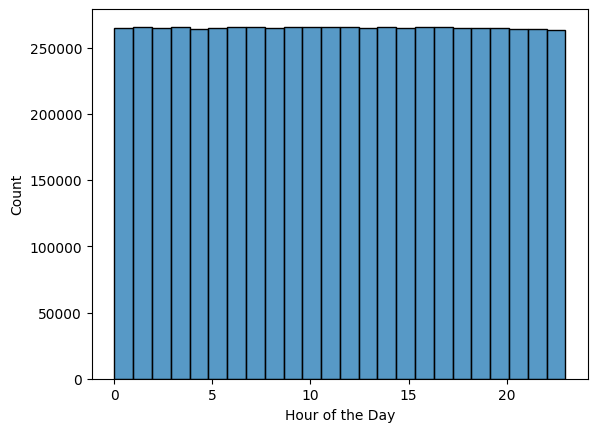

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#menampilkan distribusi hour di data train
sns.histplot(df_train['Hour'], bins=24)
plt.xlabel('Hour of the Day')

Text(0.5, 0, 'Hour of the Day')

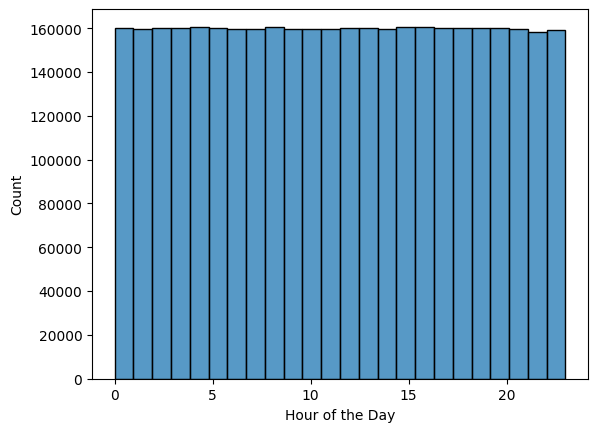

In [ ]:
#menampilkan distribusi hour di data test
sns.histplot(df_test['Hour'], bins=24)
plt.xlabel('Hour of the Day')

Text(0.5, 0, 'Day of week')

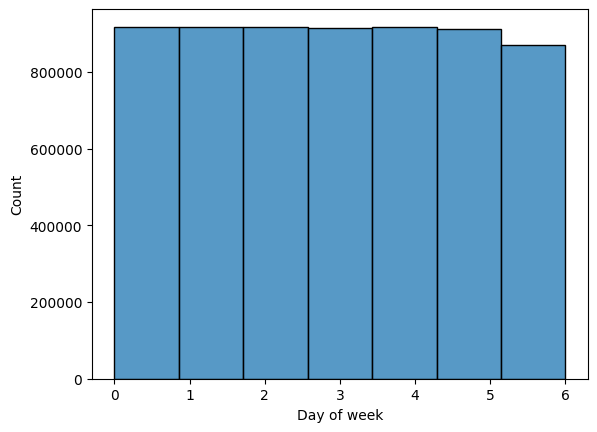

In [ ]:
#menampilkan distribusi day di data train
sns.histplot(df_train['Day_of_week'], bins=7)
plt.xlabel('Day of week')

Text(0.5, 0, 'Day of week')

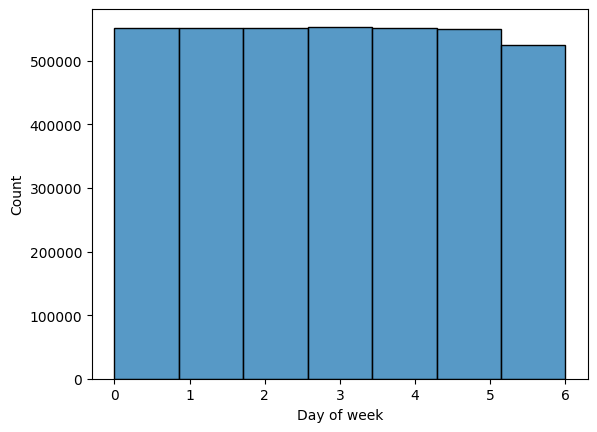

In [ ]:
#menampilkan distribusi day di data test
sns.histplot(df_test['Day_of_week'], bins=7)
plt.xlabel('Day of week')

In [ ]:
#Mengisi missing value hour dan day dengan modus
df_train['Hour'] = df_train['Hour'].fillna(df_train['Hour'].mode()[0])
df_train['Day_of_week'] = df_train['Day_of_week'].fillna(df_train['Day_of_week'].mode()[0])

df_test['Hour'] = df_test['Hour'].fillna(df_test['Hour'].mode()[0])
df_test['Day_of_week'] = df_test['Day_of_week'].fillna(df_test['Day_of_week'].mode()[0])

# Cek kembali apakah sudah terisi
print(df_train[['Hour', 'Day_of_week']].isna().sum())
print(df_test[['Hour', 'Day_of_week']].isna().sum())

Hour           0
Day_of_week    0
dtype: int64
Hour           0
Day_of_week    0
dtype: int64


In [ ]:
#ubah fitur baru ke str
cols_to_fix = ['Hour', 'Day_of_week', 'Is_Weekend']

for col in cols_to_fix:
    df_train[col] = df_train[col].astype(str)
    df_test[col] = df_test[col].astype(str)

In [ ]:
#cat features
cat_features = [
    'Pickup_Zone', 'Dropoff_Zone', 'Device_FP', 'Promo_Code',
    'Car_Model', 'Payment_Method', 'Weather', 'Traffic',
    'Signal_Strength',
    'Hour',
    'Day_of_week',
    'Is_Weekend'
]

In [ ]:
#simpan trip id untuk submission
test_ids = df_test["Trip_ID"].copy()

# drop timestamp dan trip id
df_train = df_train.drop(columns=['Trip_ID', 'Timestamp'])
df_test  = df_test.drop(columns=['Timestamp'])

In [ ]:
#hanya pakai beberapa data saja
df_train_sample = df_train.sample(frac=0.075, random_state=42)

In [ ]:
# pisahkan fitur dan label
x = df_train_sample.drop(columns='Trip_Label')
y = df_train_sample['Trip_Label']

In [ ]:
!pip install catboost
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report
from catboost import CatBoostClassifier

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 11.8 MB/s eta 0:00:00


In [ ]:
# train validation split
x_train, x_val, y_train, y_val = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
#Downsampling kelas mayor
train_df = pd.concat([x_train, y_train], axis=1)

min_size = train_df["Trip_Label"].value_counts().min()

balanced_train = (
    train_df
    .groupby("Trip_Label", group_keys=False)
    .apply(lambda x: x.sample(min_size, random_state=42))
)

X_train_bal = balanced_train.drop(columns="Trip_Label")
y_train_bal = balanced_train["Trip_Label"]


/tmp/ipython-input-3047288054.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min_size, random_state=42))


In [ ]:
#Hitung class weight
from sklearn.utils.class_weight import compute_class_weight
classes = np.unique(y_train_bal)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_bal
)

class_weights = dict(zip(classes, weights))
print(class_weights)


{'Fraud_Indication': np.float64(1.0), 'Navigation_Issue': np.float64(1.0), 'Perfect_Trip': np.float64(1.0), 'Safety_Violation': np.float64(1.0), 'Service_Complaint': np.float64(1.0)}


In [ ]:
#model catboost
model = CatBoostClassifier(
    iterations=600,
    learning_rate=0.08,
    depth=6,
    cat_features=cat_features,
    loss_function="MultiClass",
    eval_metric="TotalF1",
    random_seed=42,
    verbose=100,
    class_weights=class_weights,
    bootstrap_type="Bernoulli",
    early_stopping_rounds=50,
    subsample=0.5
)

In [ ]:
#training model
model.fit(
    X_train_bal,
    y_train_bal,
    eval_set=(x_val, y_val),
    use_best_model=True
)

0:	learn: 0.4774675	test: 0.2562422	best: 0.2562422 (0)	total: 4.7s	remaining: 46m 53s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.693690442
bestIteration = 4

Shrink model to first 5 iterations.


In [ ]:
#evaluasi
y_val_pred = model.predict(x_val)
print("Macro F1:", f1_score(y_val, y_val_pred, average="macro"))
print(classification_report(y_val, y_val_pred))

Macro F1: 0.5497886050597598
                   precision    recall  f1-score   support

 Fraud_Indication       0.86      0.94      0.90      5988
 Navigation_Issue       0.13      0.04      0.06     11905
     Perfect_Trip       0.72      0.93      0.82     66021
 Safety_Violation       0.97      0.95      0.96     24078
Service_Complaint       0.12      0.01      0.02     12008

         accuracy                           0.76    120000
        macro avg       0.56      0.58      0.55    120000
     weighted avg       0.66      0.76      0.69    120000



In [ ]:
#prediksi
x_test = df_test.drop(columns="Trip_ID")
y_test_pred = model.predict(x_test).flatten()

In [ ]:
#file submission
submission = pd.DataFrame({
    "Trip_ID": test_ids,
    "Trip_Label": y_test_pred
})

submission.to_csv("submission+downsampling+0.075.csv", index=False)

In [37]:
import joblib
nama_file_model = 'model_klasifikasi_perjalanan_catboost.joblib'

# Menyimpan/Serialisasi model
try:
    joblib.dump(model, nama_file_model)
    print(f"Model berhasil disimpan ke {nama_file_model}")
except Exception as e:
    print(f"Terjadi kesalahan saat menyimpan model: {e}")


Model berhasil disimpan ke model_klasifikasi_perjalanan_catboost.joblib
